## Задание 1. 
Разработать или взять в готовом виде генеративно-состязательную нейросеть,

способную генерировать точки трёхмерного пространства, лежащие на некоторой части за-
данной в таблице 1 поверхности. Значения всех констант (R,u,v) выбираются самостоятельно;

если поверхность не является ограниченной, границы фрагмента, в пределах которого будет
выполняться генерация, также выбираются самостоятельно.

In [7]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [8]:
torch.manual_seed(42)
np.random.seed(42)

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")

Используемое устройство: cuda


In [10]:
def generate_real_data(n_samples, variant):
    """Генерирует точки (x, y, z) на заданной поверхности."""
    if variant == 1:
        # 1. Сфера радиуса R = 2 (верхняя и нижняя полусферы)
        R = 2.0
        theta = np.random.uniform(0, 2 * np.pi, n_samples)
        cos_phi = np.random.uniform(-1, 1, n_samples)
        sin_phi = np.sqrt(1 - cos_phi**2)
        x = R * sin_phi * np.cos(theta)
        y = R * sin_phi * np.sin(theta)
        z = R * cos_phi
    elif variant == 2:
        # 2. Эллиптический параболоид z = u*x^2 + v*y^2
        u, v = 1.0, 0.5
        x = np.random.uniform(-2, 2, n_samples)
        y = np.random.uniform(-2, 2, n_samples)
        z = u * x**2 + v * y**2
    elif variant == 3:
        # 3. Гиперболический параболоид z = u*x^2 - v*y^2
        u, v = 1.0, 0.5
        x = np.random.uniform(-2, 2, n_samples)
        y = np.random.uniform(-2, 2, n_samples)
        z = u * x**2 - v * y**2
    elif variant == 4:
        # 4. Конус с вертикальной осью симметрии z = k * sqrt(x^2 + y^2)
        k = 1.5
        r = np.random.uniform(0, 2, n_samples)
        theta = np.random.uniform(0, 2 * np.pi, n_samples)
        x = r * np.cos(theta)
        y = r * np.sin(theta)
        z = k * r
    elif variant == 5:
        # 5. Тор (R = 2, r = 0.7)
        R, r = 2.0, 0.7
        theta = np.random.uniform(0, 2 * np.pi, n_samples)
        phi = np.random.uniform(0, 2 * np.pi, n_samples)
        x = (R + r * np.cos(phi)) * np.cos(theta)
        y = (R + r * np.cos(phi)) * np.sin(theta)
        z = r * np.sin(phi)
    else:
        raise ValueError("Вариант должен быть от 1 до 5")
        
    data = np.stack([x, y, z], axis=1)
    return torch.tensor(data, dtype=torch.float32)

In [11]:
def evaluate_surface_error(points, variant):
    """Вычисляет среднюю абсолютную ошибку."""
    pts = points.detach().cpu().numpy()
    x, y, z = pts[:, 0], pts[:, 1], pts[:, 2]
    
    if variant == 1:
        R = 2.0
        err = np.abs(np.sqrt(x**2 + y**2 + z**2) - R)
    elif variant == 2:
        u, v = 1.0, 0.5
        err = np.abs(z - (u * x**2 + v * y**2))
    elif variant == 3:
        u, v = 1.0, 0.5
        err = np.abs(z - (u * x**2 - v * y**2))
    elif variant == 4:
        k = 1.5
        err = np.abs(z - k * np.sqrt(x**2 + y**2))
    elif variant == 5:
        R, r = 2.0, 0.7
        err = np.abs(np.sqrt((np.sqrt(x**2 + y**2) - R)**2 + z**2) - r)
        
    return np.mean(err), np.std(err)

## Задание 2. 
Обучить нейросеть решению задачи, оценив достигаемую точность.

In [12]:
class Generator(nn.Module):
    def __init__(self, latent_dim=3, hidden_dims=[64, 64], dropout=0.0):
        super().__init__()
        layers = []
        in_dim = latent_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.LeakyReLU(0.2))
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 3))  # Выход: координаты (x, y, z)
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, hidden_dims=[64, 64], dropout=0.0):
        super().__init__()
        layers = []
        in_dim = 3  # Вход: координаты (x, y, z)
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.LeakyReLU(0.2))
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 1))
        layers.append(nn.Sigmoid())
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


=== Вариант 1: Сфера ===
[Вариант 1] Epoch 500/1500 | MAE: 0.0293
[Вариант 1] Epoch 1000/1500 | MAE: 0.0244
[Вариант 1] Epoch 1500/1500 | MAE: 0.0254


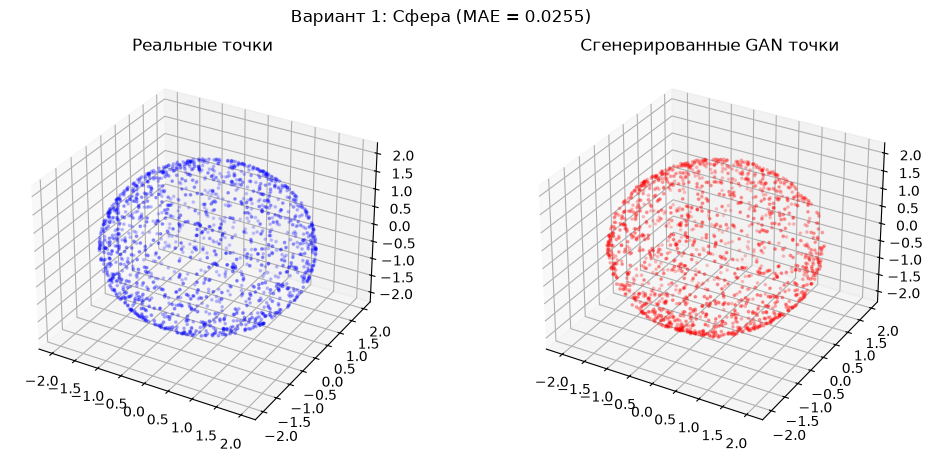


=== Вариант 2: Эллиптический параболоид ===
[Вариант 2] Epoch 500/1500 | MAE: 0.1650
[Вариант 2] Epoch 1000/1500 | MAE: 0.0932
[Вариант 2] Epoch 1500/1500 | MAE: 0.0320


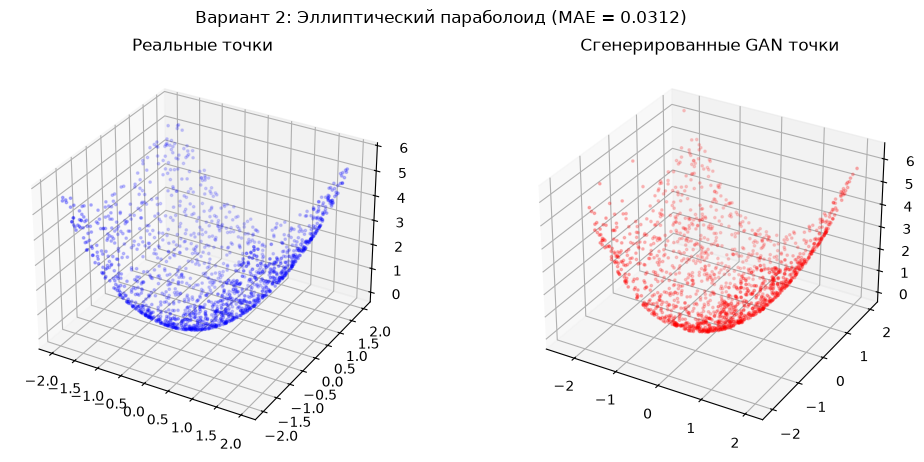


=== Вариант 3: Гиперболический параболоид ===
[Вариант 3] Epoch 500/1500 | MAE: 0.1690
[Вариант 3] Epoch 1000/1500 | MAE: 0.1193
[Вариант 3] Epoch 1500/1500 | MAE: 0.0794


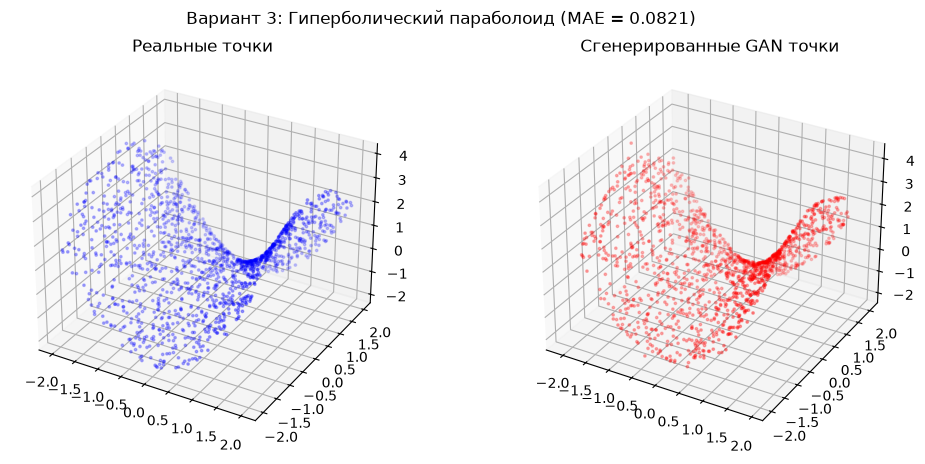


=== Вариант 4: Конус ===
[Вариант 4] Epoch 500/1500 | MAE: 0.0659
[Вариант 4] Epoch 1000/1500 | MAE: 0.0139
[Вариант 4] Epoch 1500/1500 | MAE: 0.0322


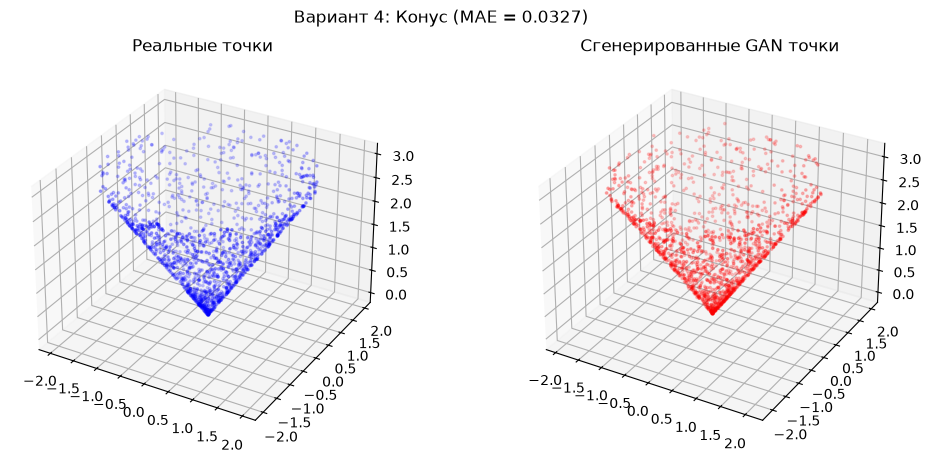


=== Вариант 5: Тор ===
[Вариант 5] Epoch 500/1500 | MAE: 0.3403
[Вариант 5] Epoch 1000/1500 | MAE: 0.3438
[Вариант 5] Epoch 1500/1500 | MAE: 0.2374


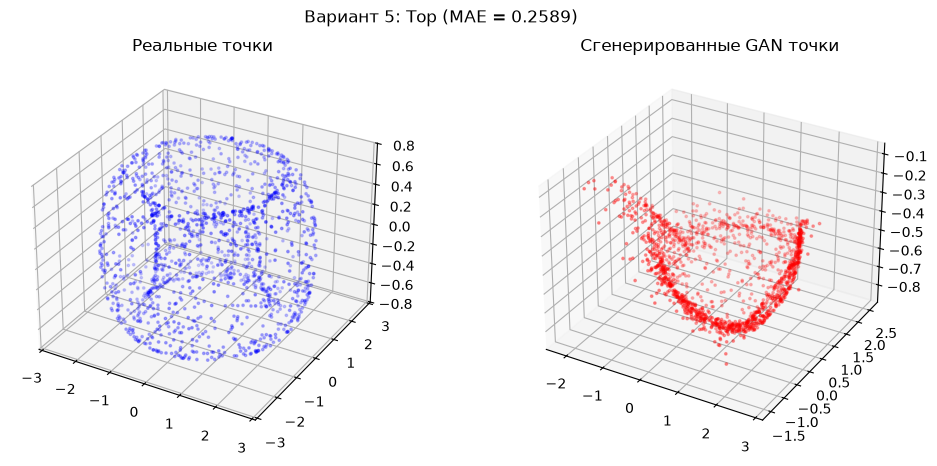

,Вариант,Поверхность,MAE,Std
0,1,Сфера,0.0255,0.0506
1,2,Эллиптический параболоид,0.0312,0.0361
2,3,Гиперболический параболоид,0.0821,0.0703
3,4,Конус,0.0327,0.0176
4,5,Тор,0.2589,0.2997


In [13]:
VARIANT_NAMES = {
    1: "Сфера",
    2: "Эллиптический параболоид",
    3: "Гиперболический параболоид",
    4: "Конус",
    5: "Тор"
}

def train_gan(variant=1, latent_dim=3, g_hidden=[64, 64], d_hidden=[64, 64], 
              dropout=0.0, epochs=1500, batch_size=128, lr=0.001, verbose=False):
    
    real_dataset = generate_real_data(4096, variant=variant)
    loader = torch.utils.data.DataLoader(real_dataset, batch_size=batch_size, shuffle=True)
    
    G = Generator(latent_dim, g_hidden, dropout).to(device)
    D = Discriminator(d_hidden, dropout).to(device)
    
    criterion = nn.BCELoss()
    opt_G = torch.optim.Adam(G.parameters(), lr=lr)
    opt_D = torch.optim.Adam(D.parameters(), lr=lr)
    
    for epoch in range(epochs):
        for real_pts in loader:
            real_pts = real_pts.to(device)
            bs = real_pts.size(0)
            
            real_labels = torch.ones(bs, 1, device=device)
            fake_labels = torch.zeros(bs, 1, device=device)
            
            # Дискриминатор
            opt_D.zero_grad()
            loss_real = criterion(D(real_pts), real_labels)
            z = torch.randn(bs, latent_dim, device=device)
            fake_pts = G(z).detach()
            loss_fake = criterion(D(fake_pts), fake_labels)
            loss_D = loss_real + loss_fake
            loss_D.backward()
            opt_D.step()
            
            # Генератор
            opt_G.zero_grad()
            z = torch.randn(bs, latent_dim, device=device)
            gen_pts = G(z)
            loss_G = criterion(D(gen_pts), real_labels)
            loss_G.backward()
            opt_G.step()
            
        if verbose and (epoch + 1) % 500 == 0:
            G.eval()
            with torch.no_grad():
                test_pts = G(torch.randn(1000, latent_dim, device=device))
                mae, _ = evaluate_surface_error(test_pts, variant=variant)
            G.train()
            print(f"[Вариант {variant}] Epoch {epoch+1}/{epochs} | MAE: {mae:.4f}")
            
    G.eval()
    with torch.no_grad():
        gen_pts = G(torch.randn(1500, latent_dim, device=device))
        mae, std = evaluate_surface_error(gen_pts, variant=variant)
        
    return G, gen_pts.cpu().numpy(), mae, std

def plot_3d_comparison(real_pts, gen_pts, title="Сравнение реальной и сгенерированной поверхностей"):
    fig = plt.figure(figsize=(12, 5))
    
    ax1 = fig.add_subplot(121, projection='3d')
    ax1.scatter(real_pts[:, 0], real_pts[:, 1], real_pts[:, 2], s=3, alpha=0.6, c='blue')
    ax1.set_title("Реальные точки")
    
    ax2 = fig.add_subplot(122, projection='3d')
    ax2.scatter(gen_pts[:, 0], gen_pts[:, 1], gen_pts[:, 2], s=3, alpha=0.6, c='red')
    ax2.set_title("Сгенерированные GAN точки")
    
    plt.suptitle(title)
    plt.show()

# Запуск базовой модели
base_summary = []

for v in range(1, 6):
    name = VARIANT_NAMES[v]
    print(f"\n=== Вариант {v}: {name} ===")
    
    G_model, gen_pts, mae, std = train_gan(
        variant=v, latent_dim=3, g_hidden=[64, 64], d_hidden=[64, 64], 
        dropout=0.0, epochs=1500, verbose=True
    )
    
    base_summary.append({
        "Вариант": v,
        "Поверхность": name,
        "MAE": round(mae, 4),
        "Std": round(std, 4)
    })
    
    real_sample = generate_real_data(1500, variant=v).numpy()
    plot_3d_comparison(real_sample, gen_pts, f"Вариант {v}: {name} (MAE = {mae:.4f})")

display(pd.DataFrame(base_summary))

## Задание 3. 
Проверить влияние на решение: (1) числа скрытых параметров, описывающих

точки; (2) структуры сетей генератора и дискриминатора, т.е. числа и размера слоёв; (3) вли-
яние dropout, т.е исключения части нейронов из сети при обучении.

In [14]:
results = []

def run_experiment(exp_name, **kwargs):
    _, _, mae, std = train_gan(epochs=1000, verbose=False, **kwargs)
    results.append({
        "Эксперимент": exp_name,
        "Latent Dim": kwargs.get("latent_dim", 3),
        "Слои G/D": str(kwargs.get("g_hidden", [64, 64])),
        "Dropout": kwargs.get("dropout", 0.0),
        "MAE (ошибка)": round(mae, 4),
        "Std": round(std, 4)
    })

print("Запуск экспериментов...")

all_exp_results = []

architectures = [
    ("Маленькая [16]", [16]),
    ("Средняя [64, 64]", [64, 64]),
    ("Глубокая [64, 64, 64, 64]", [64, 64, 64, 64]),
    ("Широкая [256, 256]", [256, 256])
]

for v in range(1, 6):
    name = VARIANT_NAMES[v]
    print(f"Выполнение Задания 3 для варианта {v} ({name})...")
    
    def run_exp(exp_name, **kwargs):
        _, _, mae, std = train_gan(variant=v, epochs=600, verbose=False, **kwargs)
        all_exp_results.append({
            "Вариант": f"{v}. {name}",
            "Эксперимент": exp_name,
            "Latent Dim": kwargs.get("latent_dim", 3),
            "Слои": str(kwargs.get("g_hidden", [64, 64])),
            "Dropout": kwargs.get("dropout", 0.0),
            "MAE": round(mae, 4),
            "Std": round(std, 4)
        })

    # 1. Latent dim
    for l_dim in [1, 2, 3, 8, 16]:
        run_exp(f"Latent={l_dim}", latent_dim=l_dim)

    # 2. Архитектура
    for arch_name, arch in architectures:
        run_exp(f"Архитектура: {arch_name}", g_hidden=arch, d_hidden=arch)

    # 3. Dropout
    for dr in [0.0, 0.1, 0.3, 0.5]:
        run_exp(f"Dropout={dr}", dropout=dr)

df_all = pd.DataFrame(all_exp_results)

# Сводная таблица: строки — эксперименты, столбцы — варианты (значения MAE)
pivot_mae = df_all.pivot(index="Эксперимент", columns="Вариант", values="MAE")
display(pivot_mae)

Запуск экспериментов...
Выполнение Задания 3 для варианта 1 (Сфера)...
Выполнение Задания 3 для варианта 2 (Эллиптический параболоид)...
Выполнение Задания 3 для варианта 3 (Гиперболический параболоид)...
Выполнение Задания 3 для варианта 4 (Конус)...
Выполнение Задания 3 для варианта 5 (Тор)...


Вариант,1. Сфера,2. Эллиптический параболоид,3. Гиперболический параболоид,4. Конус,5. Тор
Эксперимент,,,,,
Dropout=0.0,0.0208,0.2333,0.5981,0.0496,0.2048
Dropout=0.1,0.0772,0.2117,0.1365,0.0401,0.1674
Dropout=0.3,0.1312,0.1731,0.1453,0.0806,0.2297
Dropout=0.5,0.5252,0.2050,0.5792,0.0448,0.3921
Latent=1,0.4013,0.2773,0.9353,0.7149,0.5519
Latent=16,0.0272,0.1010,0.5307,0.0420,1.0484
Latent=2,0.0240,0.0718,0.3869,0.0968,0.1351
Latent=3,0.0393,0.1729,1.1386,0.0982,0.1770
Latent=8,0.0260,0.0847,0.1578,0.7316,0.0644


Контрольные вопросы

1. Как влияет на качество результатов число скрытых параметров?

При малом числе скрытых параметров генератору не хватает размерности, чтобы покрыть двумерную поверхность(dim=1). При большом числе скрытых слоев лишние измерения добавляют шум на вход генератора, из-за чего сети требуется больше эпох для сходимости, а обучение становится менее стабильным.(dim = 16). (Для конуса находит, что извлечь и улучшает результат).

2. Почему dropout может помогать обучению нейросетей?

Дропаут предотвращает переобучение, не давая нейроном заучить конкретный пример. Из-за чего большее число нейронов ищет схожую закономерность. Также, так как у нас GAN, то дропаут не дает дискриминатору быстро переобучиться и "подавить" генератор.